# VLM-EDETR: open-vocabulary detection from a text prompt

Download an image, describe the categories, and get detections with an
evidential score for each one: the Beta mean `E = α / (α + β)` and the total evidence `S = α + β`.

VLM-EDETR scores each query against CLIP text embeddings.

Run with `pixi run notebook`. Needs the VLM-EDETR checkpoint (see the
README).

In [1]:
CHECKPOINT = "../weights/vlm_edetr_lvis.pth"  # VLM-EDETR (OV-LVIS, RN50); relative to examples/
# Photo: "The Elephant in the election turned out to be a Hung Parliament",
# Gavin Anderson, CC BY-SA 2.0 (flickr.com/photos/andersondotcom/4911867169)
IMAGE_URL = "http://images.cocodataset.org/train2017/000000323489.jpg"
PROMPTS = ["elephant", "car", "traffic light", "street sign"]
SCORE_THRESHOLD = 0.5

In [2]:
import io
import urllib.request

import matplotlib.pyplot as plt
import torch
from PIL import Image

from edetr.data.lvis import clip_transforms
from edetr.visualize import draw_detections
from edetr.vlm.model import VLMEdetr, build_text_embeddings, load_vlm_checkpoint
from edetr.vlm.postprocess import VLMPostProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"

## 1. Download an image

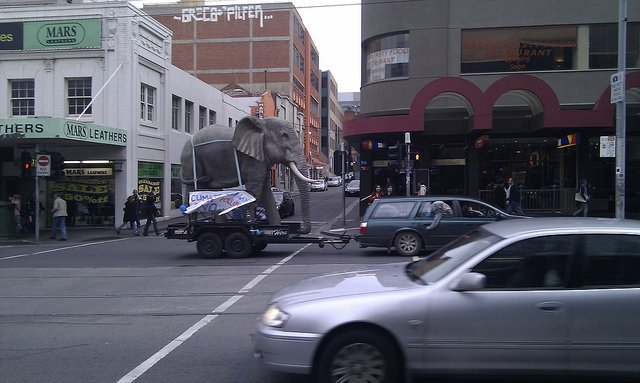

In [3]:
with urllib.request.urlopen(IMAGE_URL) as r:
    image = Image.open(io.BytesIO(r.read())).convert("RGB")
image

## 2. Load VLM-EDETR

The checkpoint holds the 1203 LVIS class embeddings, so the model is built with that
vocabulary size to load it.

In [4]:
model = VLMEdetr(num_classes=1203, multi_scale=None)
load_vlm_checkpoint(model, CHECKPOINT)
model = model.to(device).eval()

## 3. Swap in the prompt vocabulary

Each prompt becomes a CLIP text embedding, averaged over the same prompt-template ensemble
used for the LVIS classes. Replacing the model's `text_embeddings` changes what it looks
for: both the detector's Beta head and the frozen-CLIP region scores use them. (The
class-count-specific denoising embeddings are only used in training.)

In [5]:
text_embeddings = build_text_embeddings(PROMPTS, "RN50", device=device)
model.text_embeddings = text_embeddings.to(device)
text_embeddings.shape

torch.Size([4, 1024])

## 4. Run inference

Images are resized to 640x640 and CLIP-normalized. The post-processor fuses the detector score
with the frozen-CLIP region score. `uncertainty_weighted` is the uncertainty-guided fusion:
`confidence ** (1 - u) * clip ** u` with `u = 2 / S`, so where the detector has little
evidence the score leans on CLIP. `score_type="confidence"` gives the fixed F-VLM ensemble
`confidence ** (1 - a) * clip ** a` (`roi_alpha`) instead.

In [6]:
x = clip_transforms(train=False)(image).unsqueeze(0).to(device)
with torch.no_grad():
    outputs = model(x)

postprocess = VLMPostProcessor(
    num_classes=len(PROMPTS), num_top_queries=100, score_type="uncertainty_weighted"
)
w, h = image.size
det = postprocess(outputs, image_ids=[0], image_sizes=torch.tensor([[h, w]]))[0]

# alpha = E * S and beta = (1 - E) * S for the predicted class; u = 2 / S
for r in det.to_coco(with_extras=True):
    if r["score"] < SCORE_THRESHOLD:
        continue
    e, s = r["expectation"], r["concentration"]
    print(
        f"{PROMPTS[r['category_id'] - 1]:>15}  score {r['score']:.2f}  u {min(1, 2 / s):.2f}  "
        f"alpha {e * s:6.2f}  beta {(1 - e) * s:5.2f}"
    )

            car  score 0.88  u 0.05  alpha  40.08  beta  3.89
            car  score 0.87  u 0.05  alpha  39.40  beta  3.94
    street sign  score 0.79  u 0.06  alpha  26.29  beta  5.52
       elephant  score 0.78  u 0.06  alpha  25.64  beta  5.62
  traffic light  score 0.76  u 0.07  alpha  23.47  beta  5.94
    street sign  score 0.70  u 0.07  alpha  21.61  beta  6.19
            car  score 0.64  u 0.10  alpha  14.21  beta  6.62
            car  score 0.63  u 0.10  alpha  13.16  beta  6.67
    street sign  score 0.58  u 0.07  alpha  21.91  beta  6.15
            car  score 0.54  u 0.13  alpha   9.29  beta  6.66
  traffic light  score 0.51  u 0.14  alpha   7.90  beta  6.62


## 5. Draw the detections

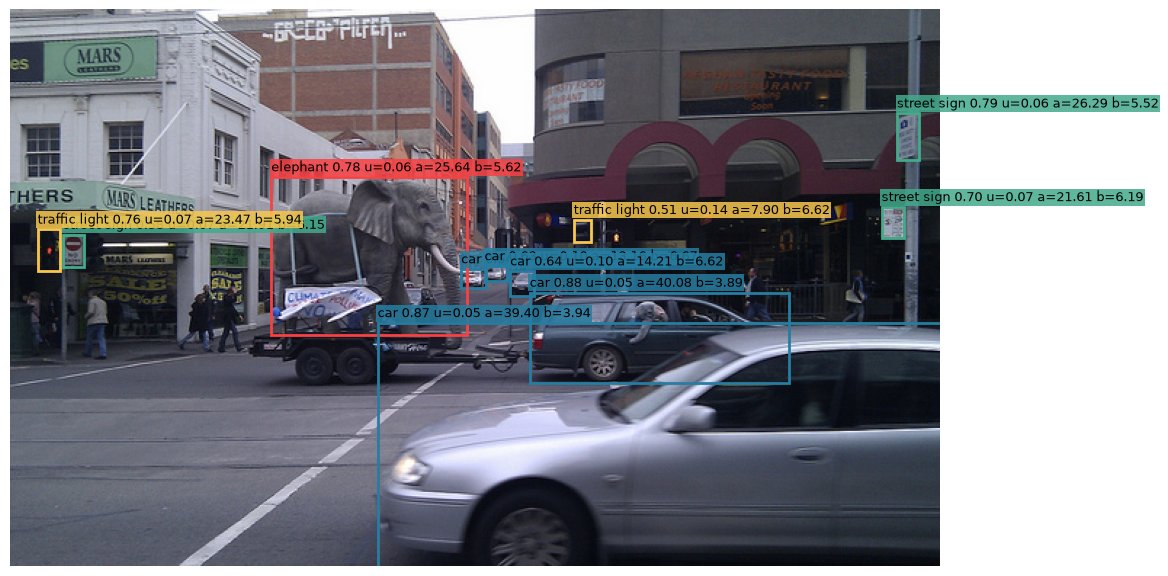

In [7]:
draw_detections(image, det, PROMPTS, SCORE_THRESHOLD)
plt.show()

Each label reads `name score u=… a=… b=…`: `a` and `b` are the Beta parameters α and β of
the predicted class, and `u = 2 / (α + β)` is its uncertainty. A high score with low `u`
means the detector has a lot of evidence; a high score with high `u` means it has little
and the score leans on CLIP. Try prompts that aren't in the image (`"giraffe"`) or other things in it (`"bus"`).